# Exploratory Data Analysis

## 1. Introduction and research questions

### 1.1 Project Objective

The objective of this exploratory data analysis (EDA) is to investigate factors associated with mental health treatment-seeking among individuals represented in the 2014 OSMI Mental Health in Tech Survey.

The analysis focuses on demographic characteristics, personal mental health history, and workplace attitudes and conditions. By examining these factors, we aim to identify patterns and relationships that may help explain differences in treatment-seeking behavior among respondents.

Additionally, this analysis will help identify potentially informative variables for subsequent statistical modeling and machine learning.

### 1.2 Research Questions

What proportion of respondents reported seeking mental health treatment?

How are demographic characteristics, such as age and gender, associated with treatment-seeking?

Is having a family history of mental illness associated with whether a respondent sought treatment?

How are workplace factors, including mental health benefits, available resources, and perceived workplace support, associated with treatment-seeking?

Are respondents' attitudes and perceptions surrounding mental health in the workplace associated with their likelihood of seeking treatment?

Which factors demonstrate the strongest associations with treatment-seeking when examined individually and in combination?

### 1.3 Dataset Description

This analysis uses the 2014 OSMI Mental Health in Tech Survey dataset. The survey collected responses concerning mental health, workplace experiences, and attitudes toward mental health in the technology industry.

The cleaned dataset used for this analysis contains 1,259 respondents and 28 columns. Variables include demographic information, employment characteristics, family history of mental illness, access to workplace mental health resources, perceptions of workplace support, and treatment-seeking behavior.

The dataset contains both categorical and numerical variables, allowing for descriptive statistical analysis, comparisons between groups, and further investigation of relationships among survey responses.

### 1.4 Main Outcome Variable: Treatment

The primary outcome variable for this analysis is treatment, which indicates whether a respondent has sought mental health treatment.

The variable has two possible responses:

Yes: The respondent reported seeking mental health treatment.

No: The respondent reported not seeking mental health treatment.

This binary variable will serve as the primary outcome throughout the analysis. Other survey variables will be examined in relation to treatment-seeking to identify potential associations.

## 2. Dataset overview and preparation

### 2.1 Loading and inspecting the Dataset

The cleaned OSMI 2014 survey dataset (`data/processed/survey_clean.csv`, produced in the data-cleaning stage) was loaded for exploratory data analysis. It is read-only here; all changes made in this notebook are in memory and are not saved back.

The dataset is stored in CSV format and contains respondent information, workplace characteristics, and mental-health-related survey responses.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from patsy import dmatrix
from scipy.stats import chi2 as chi2_dist, chi2_contingency, ttest_ind
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor


def treatment_crosstab(col):
    """Show counts and row percentages of `treatment` for each category of `col`."""
    print(f"\n{col.replace('_', ' ').title()}")
    print("Counts:")
    display(pd.crosstab(df[col], df["treatment"]))
    print("Row percentages:")
    display((pd.crosstab(df[col], df["treatment"], normalize="index") * 100).round(2))


# Load cleaned dataset
df = pd.read_csv("../data/processed/survey_clean.csv")

In [2]:
# Inspect the first five rows of the dataset
df.head()

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,Gender_raw,Country_grouped
0,2014-08-27 11:29:31,37,Female,United States,IL,Unknown,No,Yes,Often,6-25,...,No,No,Some of them,Yes,No,Maybe,Yes,No,Female,United States
1,2014-08-27 11:29:37,44,Male,United States,IN,Unknown,No,No,Rarely,More than 1000,...,Maybe,No,No,No,No,No,Don't know,No,M,United States
2,2014-08-27 11:29:44,32,Male,Canada,Non-US,Unknown,No,No,Rarely,6-25,...,No,No,Yes,Yes,Yes,Yes,No,No,Male,Canada
3,2014-08-27 11:29:46,31,Male,United Kingdom,Non-US,Unknown,Yes,Yes,Often,26-100,...,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,Male,United Kingdom
4,2014-08-27 11:30:22,31,Male,United States,TX,Unknown,No,No,Never,100-500,...,No,No,Some of them,Yes,Yes,Yes,Don't know,No,Male,United States


### 2.2 Dataset Dimensions

The dimensions of the dataset were examined to determine the number of respondents and variables available for analysis.

In [3]:
# Look at the number of rows and columns of the dataset
df.shape

(1259, 28)

The cleaned dataset contains 1,259 observations and 28 columns. Each observation represents a survey respondent, while the columns contain demographic information, workplace characteristics, and mental health related responses.

### 2.3 Column Names and Data Types

The column names and data types were examined to understand the structure of the dataset and identify which variables are numerical and which are categorical.

In [4]:
# Look at column names, data types, and non-null counts.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Timestamp                  1259 non-null   str  
 1   Age                        1259 non-null   int64
 2   Gender                     1259 non-null   str  
 3   Country                    1259 non-null   str  
 4   state                      1259 non-null   str  
 5   self_employed              1259 non-null   str  
 6   family_history             1259 non-null   str  
 7   treatment                  1259 non-null   str  
 8   work_interfere             1259 non-null   str  
 9   no_employees               1259 non-null   str  
 10  remote_work                1259 non-null   str  
 11  tech_company               1259 non-null   str  
 12  benefits                   1259 non-null   str  
 13  care_options               1259 non-null   str  
 14  wellness_program           1259 non

The dataset contains a combination of numerical and categorical variables. Age is treated as a numerical variable, while the rest of the survey responses represent categorical information. The variable types were reviewed to guide the selection of appropriate descriptive statistics, visualizations, and statistical methods.

### 2.4 Cleaning Gender column

In [5]:
print(df["Gender"].value_counts())

Gender
Male                990
Female              251
Non-binary/Other     14
Unknown               4
Name: count, dtype: int64


In [6]:
# Combine unknown, nonbinary, and other gender categories to just be "other", since all of them can be included as "other"

df["Gender"] = df["Gender"].replace({
    "Non-binary/Other": "Other",
    "Unknown": "Other"
})

In [7]:
print(df["Gender"].value_counts())

Gender
Male      990
Female    251
Other      18
Name: count, dtype: int64


Gender: The original dataset contained four categories: Male, Female, Non-binary/Other, and Unknown. The Non-binary/Other and Unknown categories were combined and relabeled as Other to retain all respondents and simplify categorical analysis. The resulting categories were Male (n = 990), Female (n = 251), and Other (n = 18).

### 2.5 Exclusions and Variable Handling

Some columns were excluded from the primary exploratory analysis because they were not necessary for answering the research questions or were redundant with cleaned variables.

- **Timestamp:** Excluded from the primary analysis because the survey submission time is not a focus of the research questions.
- **Gender_raw:** Excluded in favor of the standardized Gender variable, which consolidates inconsistent original responses.
- **Country:** Where country-level comparisons are relevant, the grouped Country_grouped variable may be used instead of the original high-cardinality Country variable.
- **state:** Not included in the primary descriptive comparisons because it contains numerous geographic categories and a large Non-US category.

The cleaned dataset on disk was left unchanged, and these exclusions apply only to the variables selected for analysis.

## 3. Descriptive Statistics and Univariate EDA

### 3.1 Age: Descriptive Statistics

Age was examined as the primary numerical variable in the dataset. Descriptive statistics were calculated to summarize the respondents' age distribution, including the mean, median, standard deviation, and range.

In [8]:
# Calculate descriptive statistics for Age
print(df["Age"].describe())

age_range = df["Age"].max() - df["Age"].min()
age_iqr = df["Age"].quantile(0.75) - df["Age"].quantile(0.25)

print("Age range:", age_range)
print("Age IQR:", age_iqr)

count    1259.000000
mean       32.069897
std         7.265565
min        18.000000
25%        27.000000
50%        31.000000
75%        36.000000
max        72.000000
Name: Age, dtype: float64
Age range: 54
Age IQR: 9.0


The respondents had a mean age of 32.07 years (SD = 7.27) and a median age of 31 years. Ages ranged from 18 to 72 years, indicating that the sample included adults across a range of age groups, with respondents concentrated around their early thirties.

### 3.2 Age: Distribution Visualizations

A histogram and boxplot were created to visualize the distribution of respondents' ages. The histogram illustrates the frequency of different ages, while the boxplot summarizes the distribution's center, spread, and potential outliers.

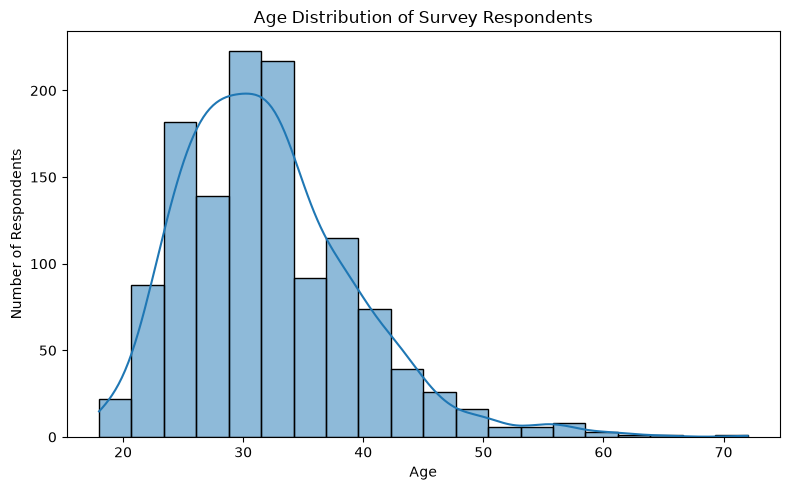

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Age Distribution of Survey Respondents")
plt.xlabel("Age")
plt.ylabel("Number of Respondents")

plt.tight_layout()
plt.show()

The distribution of ages for the respondents is unimodal and skewed to the right (or positively skewed). It peaks about 31, and has a tail to the right, as the number of respondents drops off around 32. 

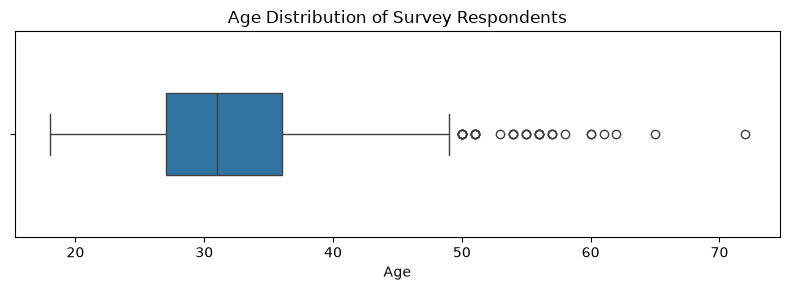

In [10]:
plt.figure(figsize=(8, 3))

sns.boxplot(data=df, x="Age", width=0.4)

plt.title("Age Distribution of Survey Respondents")
plt.xlabel("Age")

plt.tight_layout()
plt.show()

Although the majority of respondents were in their early-mid thirties, there are several outliers ranging from age 50 to 72. 

The age visualizations were examined to assess the distribution's shape, identify concentrations of respondents, and check for potential outliers. The histogram provides an overview of the frequency of ages, while the boxplot highlights the median and spread of the distribution.

### 3.3 Categorical Variables: Frequency Distributions

Frequency distributions were generated for the categorical variables to examine how respondents were distributed across different demographic, workplace, and mental-health-related response categories.

Both counts and percentages were calculated to describe the representation of each category within the sample.

In [11]:
print(df["Gender"].value_counts(dropna=False))

Gender
Male      990
Female    251
Other      18
Name: count, dtype: int64


In [12]:
# Identify categorical variables
categorical_cols = df.select_dtypes(include="object").columns.tolist()

# Exclude columns not needed for these frequency tables
exclude = ["Timestamp", "Gender_raw", "treatment"]

categorical_cols = [
    col for col in categorical_cols if col not in exclude
]

# Generate frequency tables
for col in categorical_cols:

    print(f"\n{col}")

    counts = df[col].value_counts(dropna=False)
    percentages = df[col].value_counts(
        normalize=True, dropna=False
    ) * 100

    frequency_table = pd.DataFrame({
        "Count": counts,
        "Percentage": percentages
    })

    display(frequency_table.round(2))


Gender


/tmp/ipykernel_98335/2256102704.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


,Count,Percentage
Gender,,
Male,990,78.63
Female,251,19.94
Other,18,1.43



Country


,Count,Percentage
Country,,
United States,751,59.65
United Kingdom,185,14.69
Canada,72,5.72
Germany,45,3.57
Netherlands,27,2.14
Ireland,27,2.14
Australia,21,1.67
France,13,1.03
India,10,0.79



state


... (39 outputs left out)


obs_consequence


,Count,Percentage
obs_consequence,,
No,1075,85.39
Yes,184,14.61



Country_grouped


,Count,Percentage
Country_grouped,,
United States,751,59.65
United Kingdom,185,14.69
Other,131,10.41
Canada,72,5.72
Germany,45,3.57
Netherlands,27,2.14
Ireland,27,2.14
Australia,21,1.67


### Notable Findings

Demographics and Sample Composition
- **Gender imbalance:** The sample is predominantly male (78.63%), with female respondents accounting for 19.94% and Other accounting for 1.43%.
- **Geographic concentration:** The United States (59.65%) and United Kingdom (14.69%) account for 74.34% of respondents combined.
- **Industry representation:** 81.89% of respondents work in technology companies, limiting the generalizability of findings to other industries.

Workplace Characteristics
- **Family history:** 39.08% of respondents reported a family history of mental illness.
- **Work interference:** Among respondents who provided an answer, 61.21% reported that mental-health conditions sometimes or often interfere with work.
- **Company size:** Respondents were distributed across various company sizes, with the largest groups working at companies with 6–25 employees (23.03%), 26–100 employees (22.95%), and more than 1,000 employees (22.40%).

Mental-Health Resources and Workplace Attitudes
- **Employer support:** 51.31% reported that their employer did not encourage employees to seek mental-health treatment.
- **Wellness programs:** 66.88% reported that their employer did not offer a wellness program.
- **Benefits awareness:** 32.41% were unsure whether their employer provided mental-health benefits.
- **Confidentiality awareness:** 65.05% did not know whether their employer provided anonymity protections when accessing mental-health resources.
- **Workplace stigma:** 23.19% anticipated negative consequences from discussing mental-health issues at work, compared with only 4.85% for physical-health issues.
- **Interview disclosure:** 80.06% would not discuss mental-health issues during a job interview, compared with 39.71% for physical-health issues.
- **Uncertainty about leave:** 44.72% did not know how easy it would be to take leave for mental-health reasons.

### 3.4 Treatment-Seeking Distribution

The distribution of the treatment variable was examined separately because it represents the primary outcome of interest in this study.

The number and percentage of respondents who reported seeking mental-health treatment were calculated to understand the overall distribution of the outcome.

In [13]:
treatment_counts = df["treatment"].value_counts()

treatment_summary = pd.DataFrame({
    "Count": treatment_counts,
    "Percentage": df["treatment"].value_counts(normalize=True) * 100
})

display(treatment_summary.round(2))

,Count,Percentage
treatment,,
Yes,637,50.6
No,622,49.4


Treatment-seeking was relatively evenly distributed among respondents. Of the 1,259 participants, 637 (50.60%) reported seeking mental-health treatment, while 622 (49.40%) reported not seeking treatment.

This relatively balanced distribution provides context for the subsequent analyses examining factors associated with treatment-seeking.

### 3.5 Categorical Variable Visualizations

Bar charts were created for selected categorical variables to provide a visual representation of the sample's demographic characteristics, workplace conditions, and access to mental-health resources.

These visualizations help highlight the most common response categories and provide additional context for understanding the survey population.

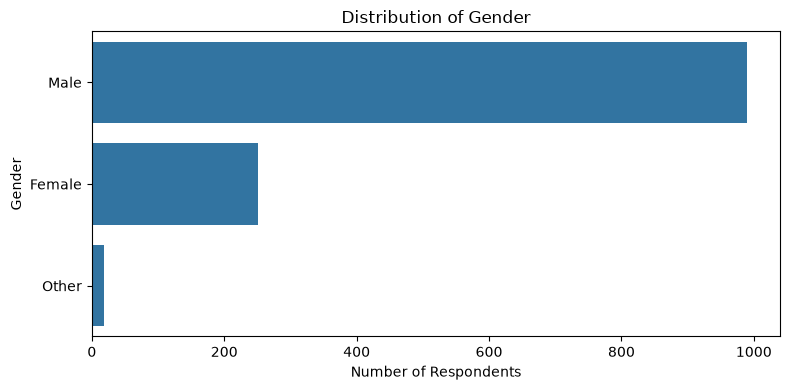

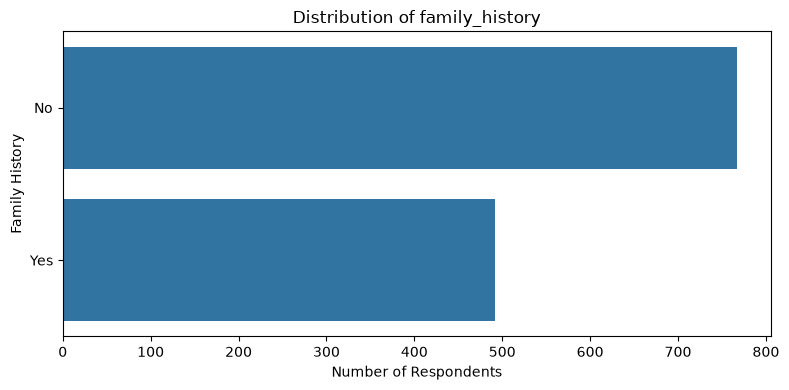

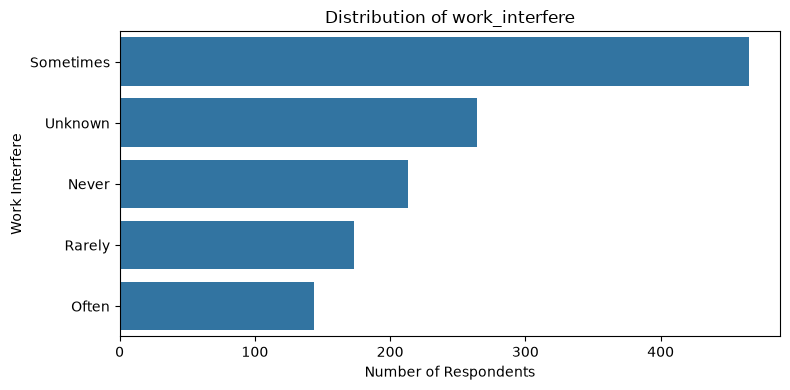

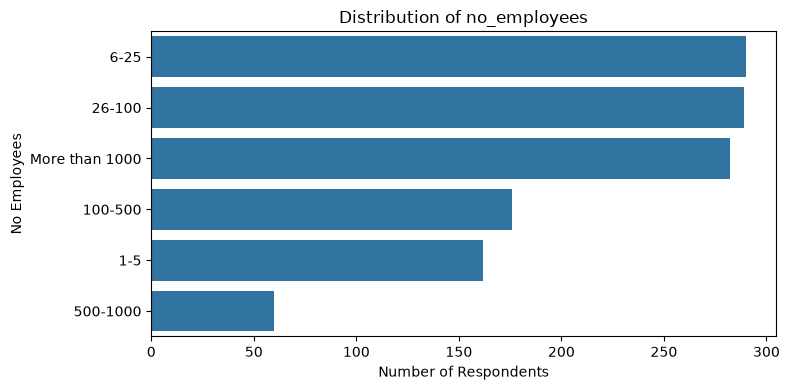

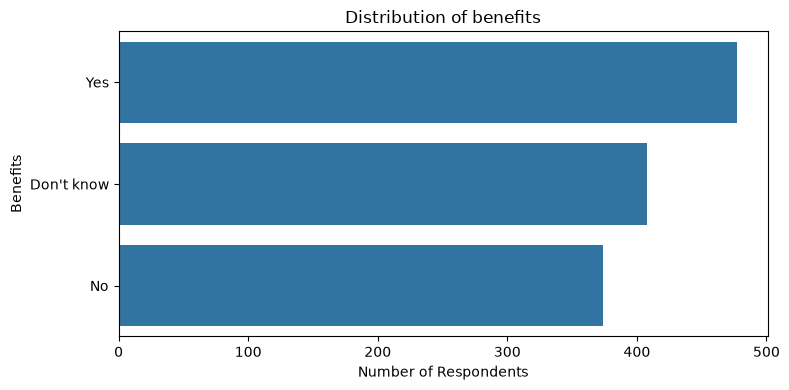

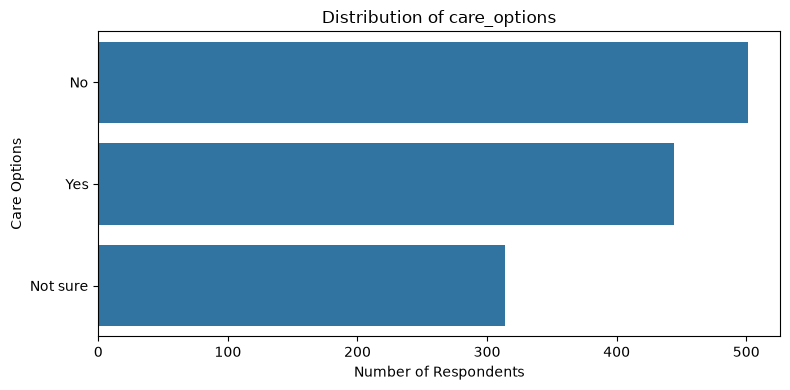

In [14]:
# Select important categorical variables to visualize
chart_cols = [
    "Gender",
    "family_history",
    "work_interfere",
    "no_employees",
    "benefits",
    "care_options"
]

for col in chart_cols:

    plt.figure(figsize=(8, 4))

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        y=col,
        order=order
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel("Number of Respondents")
    plt.ylabel(col.replace("_", " ").title())

    plt.tight_layout()
    plt.show()

The previous section examined the frequency distributions of categorical variables using counts and percentages. The above bar charts provide a visual representation of selected demographic and workplace variables, making it easier to compare category frequencies and identify patterns in the sample.

### 3.6 Summary of Descriptive Findings

The descriptive analysis provides an overview of the 1,259 respondents included in the cleaned dataset.

Participants ranged in age from 18 to 72 years, with a mean age of 32.07 (SD = 7.27) and a median age of 31.

The sample was predominantly male, and respondents represented a range of workplace characteristics and attitudes toward mental health.

Treatment-seeking was relatively evenly distributed, with 50.60% of respondents reporting that they had sought mental-health treatment and 49.40% reporting that they had not.

These descriptive findings establish the demographic and workplace context of the sample and provide a foundation for the subsequent examination of relationships between respondent characteristics, workplace factors, and treatment-seeking.

## 4. Bivariate EDA: Treatment-Seeking vs. Other Variables
Research question: Which characteristics appear related to treatment-seeking?

### 4.1 Treatment-seeking and family history
This section examines the relationship between respondents' family history of mental illness and whether they sought mental-health treatment. Row percentages are used to compare treatment-seeking rates among respondents with and without a reported family history.

In [15]:
# Calculate counts
family_treatment = pd.crosstab(
    df["family_history"],
    df["treatment"]
)

# Calculate row percentages
family_treatment_pct = pd.crosstab(
    df["family_history"],
    df["treatment"],
    normalize="index"
) * 100

# Convert counts to long format
family_treatment_table = (
    family_treatment
    .rename_axis("Family History")
    .reset_index()
    .melt(
        id_vars="Family History",
        var_name="Treatment",
        value_name="Count"
    )
)

# Convert percentages to long format
family_treatment_pct_table = (
    family_treatment_pct
    .rename_axis("Family History")
    .reset_index()
    .melt(
        id_vars="Family History",
        var_name="Treatment",
        value_name="Percentage"
    )
)

# Combine counts and percentages
family_treatment_table["Percentage"] = (
    family_treatment_pct_table["Percentage"].round(2)
)

display(family_treatment_table)

,Family History,Treatment,Count,Percentage
0,No,No,495,64.54
1,Yes,No,127,25.81
2,No,Yes,272,35.46
3,Yes,Yes,365,74.19


### 4.2 Treatment-seeking and workplace factors
Workplace characteristics were compared with treatment-seeking to explore whether employment arrangements and workplace context were associated with differences in reported treatment-seeking. Row percentages are used to compare the proportion who sought treatment within each category.

In [16]:
workplace_cols = [
    "self_employed",
    "no_employees",
    "remote_work",
    "tech_company"
]

for col in workplace_cols:
    treatment_crosstab(col)


Self Employed
Counts:


treatment,No,Yes
self_employed,,
No,545,550
Unknown,9,9
Yes,68,78


Row percentages:


treatment,No,Yes
self_employed,,
No,49.77,50.23
Unknown,50.00,50.00
Yes,46.58,53.42



No Employees
Counts:


treatment,No,Yes
no_employees,,
1-5,71,91
100-500,81,95
26-100,139,150
500-1000,33,27
6-25,162,128
More than 1000,136,146


... (6 outputs left out)


Tech Company
Counts:


treatment,No,Yes
tech_company,,
No,105,123
Yes,517,514


Row percentages:


treatment,No,Yes
tech_company,,
No,46.05,53.95
Yes,50.15,49.85


### 4.3 Treatment-seeking and mental-health attitudes
This analysis examines whether respondents' perceptions of workplace mental-health resources, support, and potential stigma differed according to treatment-seeking status. These comparisons may help identify workplace attitudes and experiences that appear related to seeking mental-health treatment.

### 4.4 Treatment-seeking and demographics
Demographic characteristics were compared with treatment-seeking to examine whether reported treatment-seeking varied across demographic groups represented in the sample.

In [17]:
demographic_cols = [
    "Gender",
    "Country_grouped"
]

for col in demographic_cols:
    treatment_crosstab(col)


Gender
Counts:


treatment,No,Yes
Gender,,
Female,78,173
Male,541,449
Other,3,15


Row percentages:


treatment,No,Yes
Gender,,
Female,31.08,68.92
Male,54.65,45.35
Other,16.67,83.33



Country Grouped
Counts:


treatment,No,Yes
Country_grouped,,
Australia,8,13
Canada,35,37
Germany,24,21
Ireland,14,13
Netherlands,18,9
Other,90,41
United Kingdom,92,93
United States,341,410


Row percentages:


treatment,No,Yes
Country_grouped,,
Australia,38.10,61.90
Canada,48.61,51.39
Germany,53.33,46.67
Ireland,51.85,48.15
Netherlands,66.67,33.33
Other,68.70,31.30
United Kingdom,49.73,50.27
United States,45.41,54.59


### 4.5 Age comparisons by treatment group
Age was compared between respondents who reported seeking mental-health treatment and those who did not. Group-level descriptive statistics were calculated to examine differences in average age, median age, and variability.

In [18]:
age_by_treatment = df.groupby("treatment")["Age"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(age_by_treatment.round(2))

,count,mean,median,std,min,max
treatment,,,,,,
No,622,31.53,31.0,6.95,18,65
Yes,637,32.59,32.0,7.53,18,72


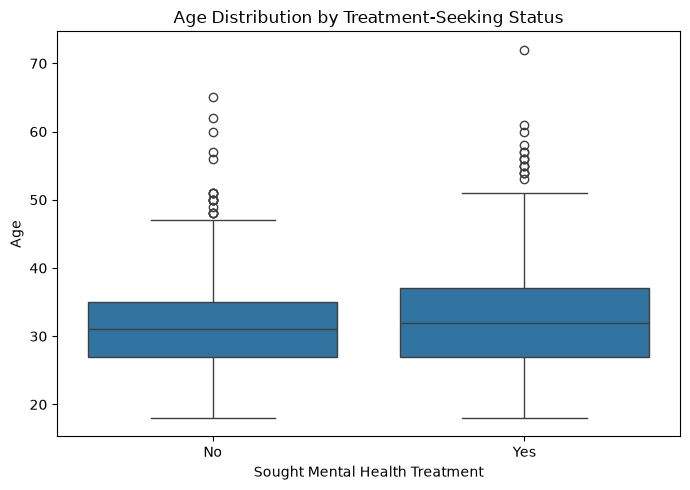

In [19]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="treatment",
    y="Age",
    order=["No", "Yes"]
)

plt.title("Age Distribution by Treatment-Seeking Status")
plt.xlabel("Sought Mental Health Treatment")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

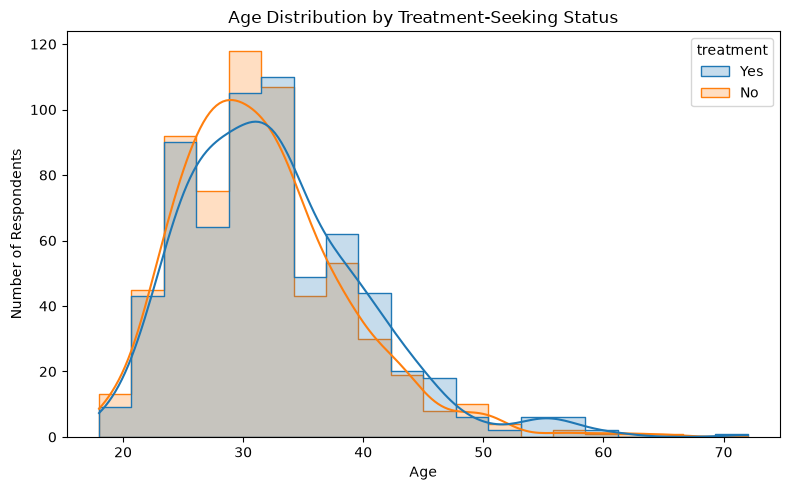

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="treatment",
    bins=20,
    kde=True,
    element="step"
)

plt.title("Age Distribution by Treatment-Seeking Status")
plt.xlabel("Age")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()

### 4.6 Identifying Notable Patterns

The bivariate analysis revealed several notable patterns in treatment-seeking:

1. **Family history:** Respondents reporting a family history of mental illness had a higher treatment-seeking rate (74.19%) than respondents without a family history (35.46%), a difference of approximately 38.73 percentage points.

2. **Gender:** Female respondents had a higher treatment-seeking rate (68.92%) than male respondents (45.35%). The "Other" category had the highest rate (83.33%), although it contained only 18 respondents.

3. **Country:** Treatment-seeking rates varied across country groups. Australia had the highest rate (61.90%), while the Netherlands (33.33%) and the "Other" group (31.30%) had the lowest. Smaller country groups had limited sample sizes, so these percentages should be interpreted cautiously.

4. **Age:** Respondents who sought treatment were slightly older on average (32.59 years) than those who did not (31.53 years). However, the similar medians (32 and 31 years) and overlapping distributions suggest relatively small age differences.

5. **Potential relationships for further testing:** Family history and gender showed particularly noticeable differences in treatment-seeking. Country group may also warrant investigation, although its smaller categories should be considered when selecting statistical tests.

Overall, family history and gender showed the most notable differences among the variables examined. These patterns will be investigated further through statistical hypothesis testing in the next section.

### 4.7 Comparison charts for strongest findings

Based on the bivariate analysis, visualizations were created for selected variables that showed notable differences in treatment-seeking rates. Percentage-based bar charts allow treatment-seeking rates to be compared across categories, while an age boxplot illustrates differences in age distributions between treatment groups.

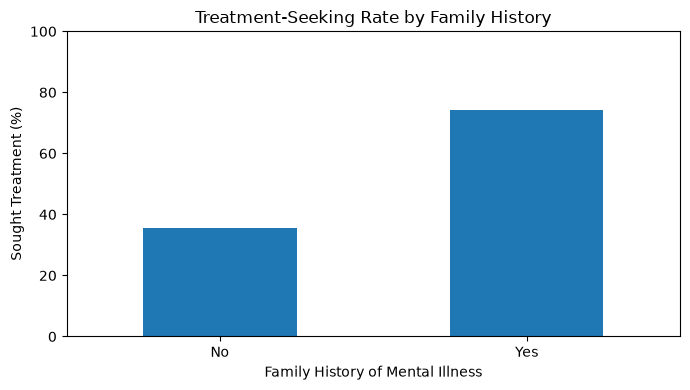

In [21]:
family_plot = pd.crosstab(
    df["family_history"],
    df["treatment"],
    normalize="index"
) * 100

family_plot["Yes"].plot(kind="bar", figsize=(7, 4))

plt.title("Treatment-Seeking Rate by Family History")
plt.xlabel("Family History of Mental Illness")
plt.ylabel("Sought Treatment (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

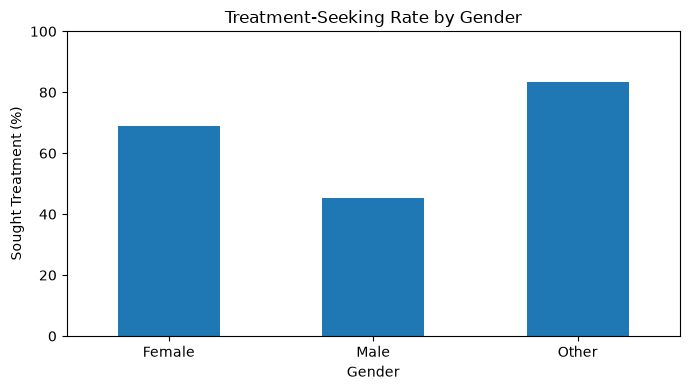

In [22]:
gender_plot = pd.crosstab(
    df["Gender"],
    df["treatment"],
    normalize="index"
) * 100

gender_plot["Yes"].plot(kind="bar", figsize=(7, 4))

plt.title("Treatment-Seeking Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Sought Treatment (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

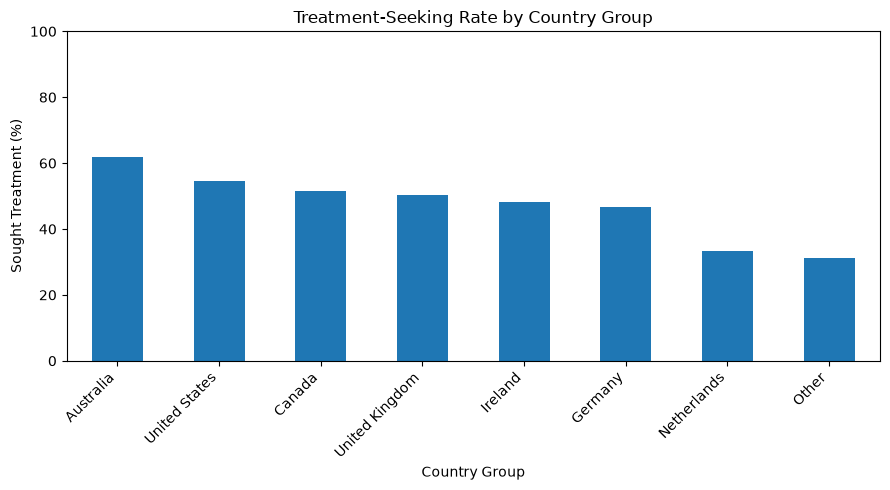

In [23]:
country_plot = pd.crosstab(
    df["Country_grouped"],
    df["treatment"],
    normalize="index"
) * 100

country_plot["Yes"].sort_values(ascending=False).plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Treatment-Seeking Rate by Country Group")
plt.xlabel("Country Group")
plt.ylabel("Sought Treatment (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

The comparison charts highlight differences in treatment-seeking rates across family history, gender, and country groups. Family history showed the largest difference, followed by gender. Country-group percentages also varied, although some categories had relatively small sample sizes. The age comparison showed more similar distributions between treatment groups.

### 4.8 Summary of bivariate findings
The bivariate analysis examined differences in treatment-seeking across demographic characteristics, family history, workplace factors, and mental-health attitudes. The most notable patterns included a substantially higher treatment-seeking rate among respondents with a family history of mental illness, differences between female and male respondents, and variation across country groups. Age comparisons showed that respondents who sought treatment were slightly older on average, although the two groups had similar age distributions.

These findings suggest that family history and gender may be particularly relevant characteristics to investigate further. The observed relationships will be examined through statistical hypothesis testing in the next section.

## 5. Statistical Hypothesis Testing
Research question: Which observed associations have statistical support, and how strong are they?

### 5.1 Introduction

Statistical hypothesis testing was conducted to evaluate whether the patterns observed in the bivariate analysis were statistically significant. Chi-square tests of independence were used to examine relationships between categorical variables and treatment-seeking. Cramér's V was calculated to measure the strength of categorical associations. An independent-samples age comparison was also conducted. Multiple-testing correction was applied to account for conducting several statistical tests.

## 5.2 Chi-square tests and Cramér's V
Chi-square tests of independence were performed to examine associations between treatment-seeking and categorical characteristics. Cramér's V was calculated alongside each test to measure the strength of the association.

In [24]:
categorical_test_cols = [
    "family_history",
    "Gender",
    "Country_grouped",
    "self_employed",
    "no_employees",
    "remote_work",
    "tech_company",
    "benefits",
    "care_options",
    "wellness_program",
    "seek_help",
    "anonymity",
    "leave",
    "mental_health_consequence",
    "phys_health_consequence",
    "mental_health_interview",
    "phys_health_interview",
    "mental_vs_physical",
    "obs_consequence",
    "work_interfere"
]

In [25]:
chi_results = []

for col in categorical_test_cols:
    table = pd.crosstab(df[col], df["treatment"])

    chi2, p, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()
    min_dimension = min(table.shape[0] - 1, table.shape[1] - 1)
    cramers_v = np.sqrt(chi2 / (n * min_dimension))

    chi_results.append({
        "Variable": col,
        "Chi-square": chi2,
        "df": dof,
        "p-value": p,
        "Cramer's V": cramers_v,
        "Minimum Expected Count": expected.min(),
        "% Expected Counts < 5": (expected < 5).mean() * 100
    })

chi_results_df = pd.DataFrame(chi_results)

display(chi_results_df.round(4))

,Variable,Chi-square,df,p-value,Cramer's V,Minimum Expected Count,% Expected Counts < 5
0,family_history,178.2668,1,0.0000,0.3763,243.0691,0.0
1,Gender,52.3344,2,0.0000,0.2039,8.8928,0.0
2,Country_grouped,28.9817,7,0.0001,0.1517,10.3749,0.0
3,self_employed,0.5291,2,0.7675,0.0205,8.8928,0.0
4,no_employees,8.7648,5,0.1188,0.0834,29.6426,0.0
5,remote_work,0.7996,1,0.3712,0.0252,185.7601,0.0
6,tech_company,1.0929,1,0.2958,0.0295,112.6418,0.0
7,benefits,64.8386,2,0.0000,0.2269,184.7720,0.0
8,care_options,94.7587,2,0.0000,0.2743,155.1295,0.0
9,wellness_program,11.4976,2,0.0032,0.0956,92.8801,0.0


### Notable Findings

- **Strongest association:** Work interference had the strongest association with treatment-seeking (Cramer's V = 0.6874, p < .001).
- **Family history:** A moderate association was observed between family history of mental illness and treatment-seeking (V = 0.3763, p < .001).
- **Workplace resources:** Care options (V = 0.2743, p < .001) and mental-health benefits (V = 0.2269, p < .001) also showed moderate associations with treatment-seeking.
- **Gender:** A moderate association was observed between gender and treatment-seeking (V = 0.2039, p < .001).
- **Other significant associations:** Country, anonymity, leave, mental-health consequences, interview attitudes, and observed consequences showed weaker associations with treatment-seeking.
- **Negligible associations:** Wellness programs and employer encouragement to seek help were statistically significant but had very small effect sizes.
- **Non-significant results:** Self-employment, company size, remote work, tech company status, and both physical-health attitude variables did not show statistically significant associations with treatment-seeking.

**Assumptions:** All chi-square tests met the expected-frequency guideline, with no expected cell counts below 5.

**Note:** Statistical significance does not establish causation or indicate the direction of an association. Cross-tabulations and row percentages are needed to investigate group differences.

### 5.3 Age comparison: independent-samples t-test
An independent-samples Welch's t-test was conducted to compare the mean ages of respondents who reported seeking treatment and those who did not. The test evaluates whether the difference in average age between the two groups is statistically significant.

In [26]:
age_no = df.loc[df["treatment"] == "No", "Age"]
age_yes = df.loc[df["treatment"] == "Yes", "Age"]

age_test = ttest_ind(
    age_yes,
    age_no,
    equal_var=False
)

print("Mean age (No treatment):", age_no.mean())
print("Mean age (Sought treatment):", age_yes.mean())
print("Mean difference:", age_yes.mean() - age_no.mean())
print("t-statistic:", age_test.statistic)
print("p-value:", age_test.pvalue)

Mean age (No treatment): 31.532154340836012
Mean age (Sought treatment): 32.59497645211931
Mean difference: 1.0628221112832996
t-statistic: 2.60345673700903
p-value: 0.009337929430115514


### Notable Findings

- **Age and treatment-seeking:** Respondents who sought mental-health treatment had a higher mean age (32.59 years) than those who did not (31.53 years).
- **Statistical significance:** An independent-samples t-test indicated a statistically significant difference in mean age between the two groups (t = 2.60, p = 0.0093).
- **Interpretation:** Although the difference was statistically significant, the mean age difference was relatively small (approximately 1.06 years), suggesting a limited practical difference between the groups.

**Conclusion:** Age was statistically significantly associated with treatment-seeking, although the observed difference in average age was small. This finding does not establish a causal relationship.

### 5.4 Multiple-testing correction
A Benjamini-Hochberg correction was applied to the chi-square test p-values to account for multiple comparisons. This reduces the likelihood of incorrectly identifying associations as statistically significant when conducting multiple hypothesis tests.

In [27]:
chi_results_df["Adjusted p-value"] = multipletests(
    chi_results_df["p-value"],
    method="fdr_bh"
)[1]

chi_results_df["Significant"] = (
    chi_results_df["Adjusted p-value"] < 0.05
)

display(
    chi_results_df.sort_values("Adjusted p-value").round(4)
)

,Variable,Chi-square,df,p-value,Cramer's V,Minimum Expected Count,% Expected Counts < 5,Adjusted p-value,Significant
19,work_interfere,594.9243,4,0.0000,0.6874,71.1422,0.0,0.0000,True
0,family_history,178.2668,1,0.0000,0.3763,243.0691,0.0,0.0000,True
8,care_options,94.7587,2,0.0000,0.2743,155.1295,0.0,0.0000,True
7,benefits,64.8386,2,0.0000,0.2269,184.7720,0.0,0.0000,True
1,Gender,52.3344,2,0.0000,0.2039,8.8928,0.0,0.0000,True
18,obs_consequence,30.1395,1,0.0000,0.1547,90.9039,0.0,0.0000,True
11,anonymity,26.4219,2,0.0000,0.1449,32.1128,0.0,0.0000,True
12,leave,29.9435,4,0.0000,0.1542,48.4162,0.0,0.0000,True
13,mental_health_consequence,22.3273,2,0.0000,0.1332,144.2605,0.0,0.0000,True
2,Country_grouped,28.9817,7,0.0001,0.1517,10.3749,0.0,0.0003,True


### Interpretation of Chi-Square Tests

The chi-square tests identified **14 statistically significant associations** with treatment-seeking after Benjamini-Hochberg correction.

- **Strongest association:** Work interference (Cramér's V = 0.6874).
- **Moderate associations:** Family history (V = 0.3763), care options (V = 0.2743), benefits (V = 0.2269), and gender (V = 0.2039).
- **Other significant associations:** Observed consequences, anonymity, leave policies, mental-health consequences, country, mental versus physical health attitudes, interview attitudes, wellness programs, and encouragement to seek help. These generally had weaker effect sizes.
- **Non-significant variables:** Self-employment, company size, remote work, tech company status, physical-health consequences, and physical-health interview attitudes.

All tests met the expected-frequency guideline, with no expected counts below 5. However, the small sample size in the Other gender category warrants caution.

**Conclusion:** Work interference had the strongest relationship with treatment-seeking. Several individual and workplace factors were also significantly associated, although statistical significance does not imply causation.

## 6. Relationships Between Independent Variables
Research question: Are some predictors overlapping or related to one another?

### 6.1 Introduction

This section examines relationships between independent variables to identify potential overlaps among predictors. Associations between workplace characteristics, mental-health attitudes, and family history are explored. These relationships are important to consider before multivariable analysis, as highly related predictors may introduce multicollinearity into a regression model.

### 6.2 Associations between workplace variables
Categorical workplace variables were compared to explore whether respondents reporting one form of workplace support or experience also tended to report others.

In [28]:
workplace_cols = [
    "benefits",
    "care_options",
    "wellness_program",
    "seek_help",
    "anonymity",
    "leave",
    "work_interfere"
]

def cramers_v(x, y):
    table = pd.crosstab(x, y)

    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    min_dim = min(table.shape[0] - 1, table.shape[1] - 1)

    return np.sqrt(chi2 / (n * min_dim))

workplace_assoc = pd.DataFrame(
    index=workplace_cols,
    columns=workplace_cols,
    dtype=float
)

for col1 in workplace_cols:
    for col2 in workplace_cols:
        workplace_assoc.loc[col1, col2] = cramers_v(
            df[col1], df[col2]
        )

display(workplace_assoc.round(3))

,benefits,care_options,wellness_program,seek_help,anonymity,leave,work_interfere
benefits,1.000,0.426,0.351,0.443,0.285,0.207,0.134
care_options,0.426,1.000,0.290,0.317,0.294,0.131,0.163
wellness_program,0.351,0.290,1.000,0.530,0.219,0.144,0.103
seek_help,0.443,0.317,0.530,1.000,0.264,0.190,0.122
anonymity,0.285,0.294,0.219,0.264,1.000,0.277,0.090
leave,0.207,0.131,0.144,0.190,0.277,1.000,0.117
work_interfere,0.134,0.163,0.103,0.122,0.090,0.117,1.000


### Interpretation of Correlation Matrix

The correlation matrix shows generally weak to moderate positive relationships between workplace mental-health support variables.

- **Strongest relationship:** Wellness programs and encouragement to seek help (r = 0.530).
- **Other notable relationships:** Benefits and encouragement to seek help (r = 0.443), and benefits and care options (r = 0.426).
- **Weakest relationship:** Anonymity and work interference (r = 0.090).

Overall, workplace support policies and resources tend to be related to one another, suggesting that organizations providing one form of mental-health support may also provide others. However, none of the correlations are especially strong, and correlation does not establish causation.

### 6.3 Relationships between family history and other factors

Family history was compared with selected workplace and mental-health variables to explore whether respondents reporting a family history of mental illness also differed in their workplace experiences or attitudes.

In [29]:
family_related_cols = [
    "work_interfere",
    "benefits",
    "care_options",
    "wellness_program",
    "seek_help",
    "anonymity",
    "leave"
]

family_assoc = pd.Series({
    col: cramers_v(df["family_history"], df[col])
    for col in family_related_cols
}).sort_values(ascending=False)

display(family_assoc.round(3))

work_interfere      0.357
benefits            0.150
care_options        0.125
anonymity           0.077
leave               0.075
wellness_program    0.065
seek_help           0.058
dtype: float64

### Interpretation of Correlation with Treatment-Seeking

Work interference had the strongest correlation with treatment-seeking (r = 0.357), followed by benefits (r = 0.150) and care options (r = 0.125). Anonymity, leave, wellness programs, and encouragement to seek help had weaker correlations (r = 0.058–0.077).

Overall, work interference showed the clearest relationship with treatment-seeking, while workplace support factors had relatively weak relationships. These correlations do not imply causation.

### 6.4 Appropriate correlation analysis

Spearman's rank correlation was used to explore relationships involving age and selected ordinal variables. Nominal categorical variables were excluded because their categories do not have a meaningful numerical order.

In [30]:
ordinal_mapping = {
    "Never": 0,
    "Rarely": 1,
    "Sometimes": 2,
    "Often": 3
}

correlation_df = df[["Age", "work_interfere"]].copy()

# Convert work interference categories to ordinal values
correlation_df["work_interfere"] = (
    correlation_df["work_interfere"].map(ordinal_mapping)
)

# Exclude Unknown responses
correlation_df = correlation_df.dropna()

# Calculate Spearman correlation
spearman_results = correlation_df.corr(method="spearman")

display(spearman_results.round(3))

print("Sample size:", len(correlation_df))

,Age,work_interfere
Age,1.000,-0.027
work_interfere,-0.027,1.000


Sample size: 995


### Interpretation of Age and Work Interference

Age and work interference had a negligible negative correlation (r = -0.027), indicating virtually no linear relationship between respondents' age and how much mental health interfered with their work. This suggests that work interference did not meaningfully vary with age in this sample.

### 6.5 Visualizing predictor associations

A Cramér's V heatmap was created to visualize the strength of associations between categorical workplace variables. Higher values indicate stronger associations, while values closer to zero indicate weaker associations.

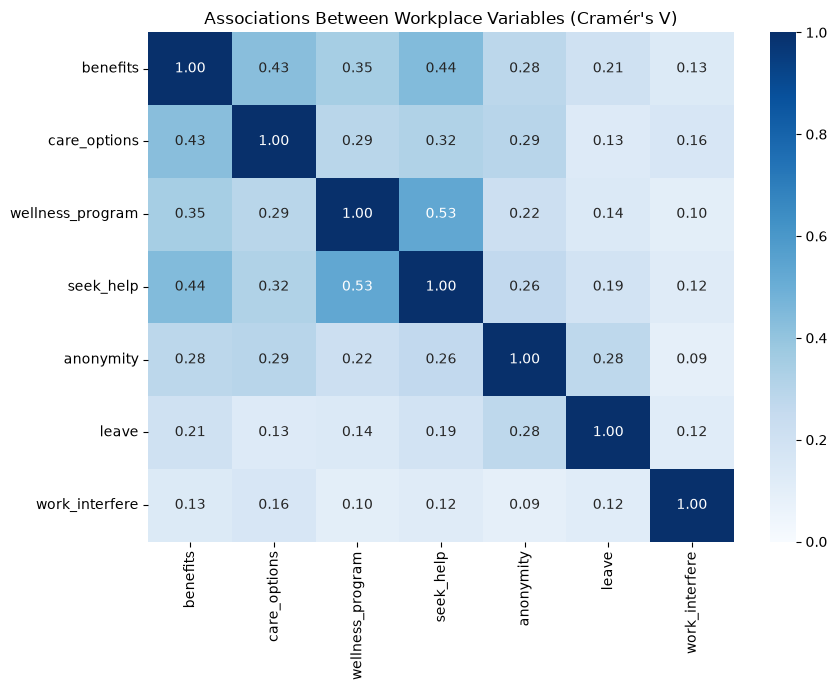

In [31]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    workplace_assoc.astype(float),
    annot=True,
    cmap="Blues",
    vmin=0,
    vmax=1,
    fmt=".2f"
)

plt.title("Associations Between Workplace Variables (Cramér's V)")
plt.tight_layout()
plt.show()

### 6.6 Checking for multicollinearity

Multicollinearity occurs when two or more independent variables are highly related to one another. This can make regression coefficients less stable and difficult to interpret. Variance Inflation Factors (VIF) will be examined for the predictors selected for the subsequent logistic regression model.

In [32]:
predictors = [
    "Age",
    "family_history",
    "Gender",
    "work_interfere",
    "benefits",
    "care_options"
]

formula = " + ".join(predictors)

X = dmatrix(formula, df, return_type="dataframe")

X = X.drop(columns="Intercept", errors="ignore")

vif_df = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

display(vif_df.sort_values("VIF", ascending=False).round(3))

,Variable,VIF
5,work_interfere[T.Sometimes],2.202
8,benefits[T.Yes],1.918
6,work_interfere[T.Unknown],1.783
7,benefits[T.No],1.673
4,work_interfere[T.Rarely],1.652
10,care_options[T.Yes],1.611
3,work_interfere[T.Often],1.591
9,care_options[T.Not sure],1.346
0,family_history[T.Yes],1.179
1,Gender[T.Male],1.129


VIF values were calculated for the six selected predictors. All values were below 5, ranging from 1.049 to 2.202. The highest VIF belonged to work_interfere[T.Sometimes] (2.202). These results indicate no concerning multicollinearity among the predictors. Therefore, all six variables were retained for the logistic regression model.

### 6.7 Interpretation of Predictor Relationships

Workplace variables showed generally weak to moderate relationships with one another. The strongest correlation was between wellness programs and encouragement to seek help (r = 0.530), followed by benefits and encouragement to seek help (r = 0.443).

Work interference had the strongest correlation with treatment-seeking (r = 0.357), while family history also showed a moderate association with treatment-seeking in the earlier hypothesis tests.

Age had a negligible correlation with work interference (r = -0.027), suggesting virtually no relationship between age and work interference.

No concerning multicollinearity was identified. All VIF values were below 5, ranging from 1.049 to 2.202, so all six selected predictors were retained for logistic regression.

## 7. Multivariable Analysis: Logistic Regression
Research question: Which factors remain associated with treatment-seeking when considered together?

### 7.1 Introduction

This section uses binary logistic regression to examine which demographic, personal, and workplace factors are associated with treatment-seeking when considered simultaneously. Unlike the bivariate analyses, logistic regression estimates the relationship between each predictor and treatment-seeking while adjusting for the other variables included in the model.

The outcome variable is `treatment`, coded as a binary outcome. Results will be interpreted using adjusted odds ratios, confidence intervals, and model performance measures.

### 7.2 Predictor Selection

Predictors were selected based on their theoretical relevance to treatment-seeking, patterns observed in the bivariate analysis, and potential overlap identified in the previous section. The selected variables represent demographic characteristics, family history, workplace experiences, and access to mental-health resources.

The outcome variable is `treatment`, with "Yes" representing respondents who sought treatment and "No" representing respondents who did not.

### 7.3 Prepare the data and fit the model
We'll use statsmodels because it provides the regression coefficients, p-values, and confidence intervals we need for interpretation.

In [33]:
df["treatment_binary"] = df["treatment"].map({
    "No": 0,
    "Yes": 1
})

df["treatment_binary"].value_counts()

treatment_binary
1    637
0    622
Name: count, dtype: int64

In [34]:
model = smf.logit(
    """
    treatment_binary ~ Age
    + C(Gender)
    + C(family_history)
    + C(work_interfere)
    + C(benefits)
    + C(care_options)
    """,
    data=df
).fit()

print(model.summary())

Optimization terminated successfully.
         Current function value: 0.373616
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:       treatment_binary   No. Observations:                 1259
Model:                          Logit   Df Residuals:                     1246
Method:                           MLE   Df Model:                           12
Date:                Sun, 22 Nov 2026   Pseudo R-squ.:                  0.4609
Time:                        11:24:51   Log-Likelihood:                -470.38
converged:                       True   LL-Null:                       -872.58
Covariance Type:            nonrobust   LLR p-value:                1.883e-164
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept                         -2.5646      0.482     -5.321     

### 7.4 Adjusted odds ratios and confidence intervals
The regression coefficients are expressed in log-odds, which are difficult to interpret directly. Exponentiating them gives adjusted odds ratios (AORs).

In [35]:
or_results = pd.DataFrame({
    "Odds Ratio": np.exp(model.params),
    "CI Lower": np.exp(model.conf_int()[0]),
    "CI Upper": np.exp(model.conf_int()[1]),
    "p-value": model.pvalues
})

display(or_results.round(3))

,Odds Ratio,CI Lower,CI Upper,p-value
Intercept,0.077,0.030,0.198,0.000
C(Gender)[T.Male],0.493,0.319,0.761,0.001
C(Gender)[T.Other],1.400,0.296,6.629,0.672
C(family_history)[T.Yes],2.609,1.863,3.654,0.000
C(work_interfere)[T.Often],30.473,16.005,58.020,0.000
C(work_interfere)[T.Rarely],11.312,6.569,19.482,0.000
C(work_interfere)[T.Sometimes],17.035,10.551,27.502,0.000
C(work_interfere)[T.Unknown],0.101,0.035,0.297,0.000
C(benefits)[T.No],0.949,0.612,1.472,0.815
C(benefits)[T.Yes],1.704,1.074,2.705,0.024


### 7.5 Assessing model fit

In [36]:
null_model = smf.logit(
    "treatment_binary ~ 1",
    data=df
).fit(disp=False)

lr_stat = 2 * (model.llf - null_model.llf)
lr_df = int(model.df_model)
lr_p = chi2_dist.sf(lr_stat, lr_df)

print("Likelihood-ratio statistic:", round(lr_stat, 3))
print("Degrees of freedom:", lr_df)
print("Likelihood-ratio p-value:", round(lr_p, 4))
print("Pseudo R-squared:", round(model.prsquared, 4))
print("AIC:", round(model.aic, 3))

Likelihood-ratio statistic: 804.401
Degrees of freedom: 12
Likelihood-ratio p-value: 0.0
Pseudo R-squared: 0.4609
AIC: 966.765


### 7.6 Assessing predictive performance

In [37]:
predicted_probabilities = model.predict(df)
predicted_classes = (predicted_probabilities >= 0.5).astype(int)

print("Accuracy:", round(
    accuracy_score(df["treatment_binary"], predicted_classes), 3
))
print("Precision:", round(
    precision_score(df["treatment_binary"], predicted_classes), 3
))
print("Recall:", round(
    recall_score(df["treatment_binary"], predicted_classes), 3
))
print("F1-score:", round(
    f1_score(df["treatment_binary"], predicted_classes), 3
))
print("ROC-AUC:", round(
    roc_auc_score(df["treatment_binary"], predicted_probabilities), 3
))

print("\nConfusion matrix:")
print(confusion_matrix(df["treatment_binary"], predicted_classes))

Accuracy: 0.836
Precision: 0.787
Recall: 0.926
F1-score: 0.851
ROC-AUC: 0.907

Confusion matrix:
[[462 160]
 [ 47 590]]


### 7.7 Interpretation of Logistic Regression Results

The logistic regression examined whether demographic, personal, and workplace characteristics were associated with treatment-seeking when considered simultaneously.

The predictors that remained statistically significant after adjustment were **gender, family history, work interference, benefits, and care options**. Age was borderline significant (p = 0.050). Among these, **work interference had the strongest adjusted association** with treatment-seeking. Respondents reporting that mental health sometimes interfered with work had 17.04 times the odds of seeking treatment compared with those reporting that it never interfered (95% CI: 10.55–27.50). Those reporting that it often interfered had even higher odds (OR = 30.47, 95% CI: 16.01–58.02).

Family history was also strongly associated with treatment-seeking. Respondents with a family history of mental health conditions had 2.61 times the odds of seeking treatment compared with those without a family history (95% CI: 1.86–3.65). Respondents who reported that their employer provided mental health benefits and care options also had higher odds of seeking treatment.

Compared with the bivariate findings, several associations remained significant after adjustment, including family history, gender, work interference, benefits, and care options. However, associations involving wellness programs, encouragement to seek help, anonymity, and several other workplace factors did not remain significant in the adjusted model. This suggests that some relationships observed in the bivariate analyses may overlap with other characteristics included in the model.

The overall model fit significantly better than the intercept-only model (likelihood-ratio statistic = 804.40, p < .001). The pseudo R-squared was 0.461. Predictive performance was also strong, with 83.6% accuracy, 78.7% precision, 92.6% recall, an F1-score of 0.851, and a ROC-AUC of 0.907. The model correctly identified 590 respondents who sought treatment and 462 who did not.

### 7.8 Limitations

Several limitations should be considered when interpreting the logistic regression results:

- **Observational data:** The associations identified do not establish causation.
- **Self-reported responses:** Responses may be affected by recall bias or differences in how participants interpret questions.
- **Sample representation:** The survey respondents may not represent the entire technology workforce.
- **Unmeasured factors:** Other characteristics that influence treatment-seeking may not be included in the dataset.
- **Model selection:** Results depend on which predictors are included and how categorical variables are grouped.
- **Statistical significance:** A statistically significant association does not necessarily indicate a large or practically meaningful effect.

Therefore, the findings should be interpreted as associations within this survey sample rather than evidence of causal relationships.

### 8.1 Summary of Key Findings

The analysis identified several factors associated with mental health treatment-seeking among respondents. Work interference had the strongest association with treatment-seeking, followed by family history of mental health conditions. Workplace benefits and care options were also associated with higher odds of seeking treatment. Demographic differences, particularly gender, were observed as well.

The findings also highlighted gaps in workplace mental health support and awareness. Many respondents were unsure whether their employers provided mental health benefits, guaranteed anonymity, or made taking mental health leave easy. Additionally, respondents reported greater concern about negative consequences when discussing mental health compared with physical health.

Overall, the results suggest that both personal experiences and workplace-related factors are associated with treatment-seeking. However, these findings represent associations rather than causal relationships.

### 8.2 Potential Predictors for Future ML Work

Based on the logistic regression results, several variables may be useful predictors for future machine learning models. These include `work_interfere`, `family_history`, `Gender`, `benefits`, `care_options`, and `Age`. Work interference and family history were particularly strong predictors in the adjusted analysis.

Additional workplace variables, such as `wellness_program`, `seek_help`, `anonymity`, and `leave`, could also be explored in future models. Although some were not statistically significant after adjustment, they may still provide useful information when combined with other features or evaluated using different modeling approaches.

Future modeling should use separate training and testing datasets, along with cross-validation, to assess how well models generalize to unseen data.

### 8.3 Limitations

Several limitations should be considered when interpreting the findings. First, the sample was predominantly male, with most respondents located in the United States and United Kingdom. Additionally, most participants worked for technology companies, limiting the generalizability of the results to other populations and industries.

Second, the dataset relies on self-reported responses, which may be affected by recall bias or differences in how participants interpret questions. Some variables also contained substantial numbers of unknown or uncertain responses, which may affect the interpretation of certain relationships.

Finally, the observational nature of the dataset means that associations cannot establish causation. The logistic regression model was also evaluated on the same dataset used for fitting, so its reported predictive performance may be overly optimistic. Evaluation on an independent test set would provide a more reliable estimate of its performance on new data.

### 8.4 Future Research

Future research could examine whether these findings hold across more diverse populations, including different industries, countries, and demographic groups. Further investigation could also explore how workplace mental health resources, awareness, and stigma influence employees' decisions to seek treatment.

Additionally, future studies could investigate the relationship between work interference and treatment-seeking in greater detail, including whether this relationship differs across demographic groups. From a machine learning perspective, comparing logistic regression with other classification methods and evaluating models on independent datasets could help determine whether treatment-seeking can be predicted reliably using these characteristics.